In [ ]:
import pandas as pd

# Load the dataset into df
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/historical_automobile_sales.csv"
df = pd.read_csv(URL)
print("Dataset loaded successfully!")

Dataset loaded successfully!


RecessionReportgraphs.png created successfully!


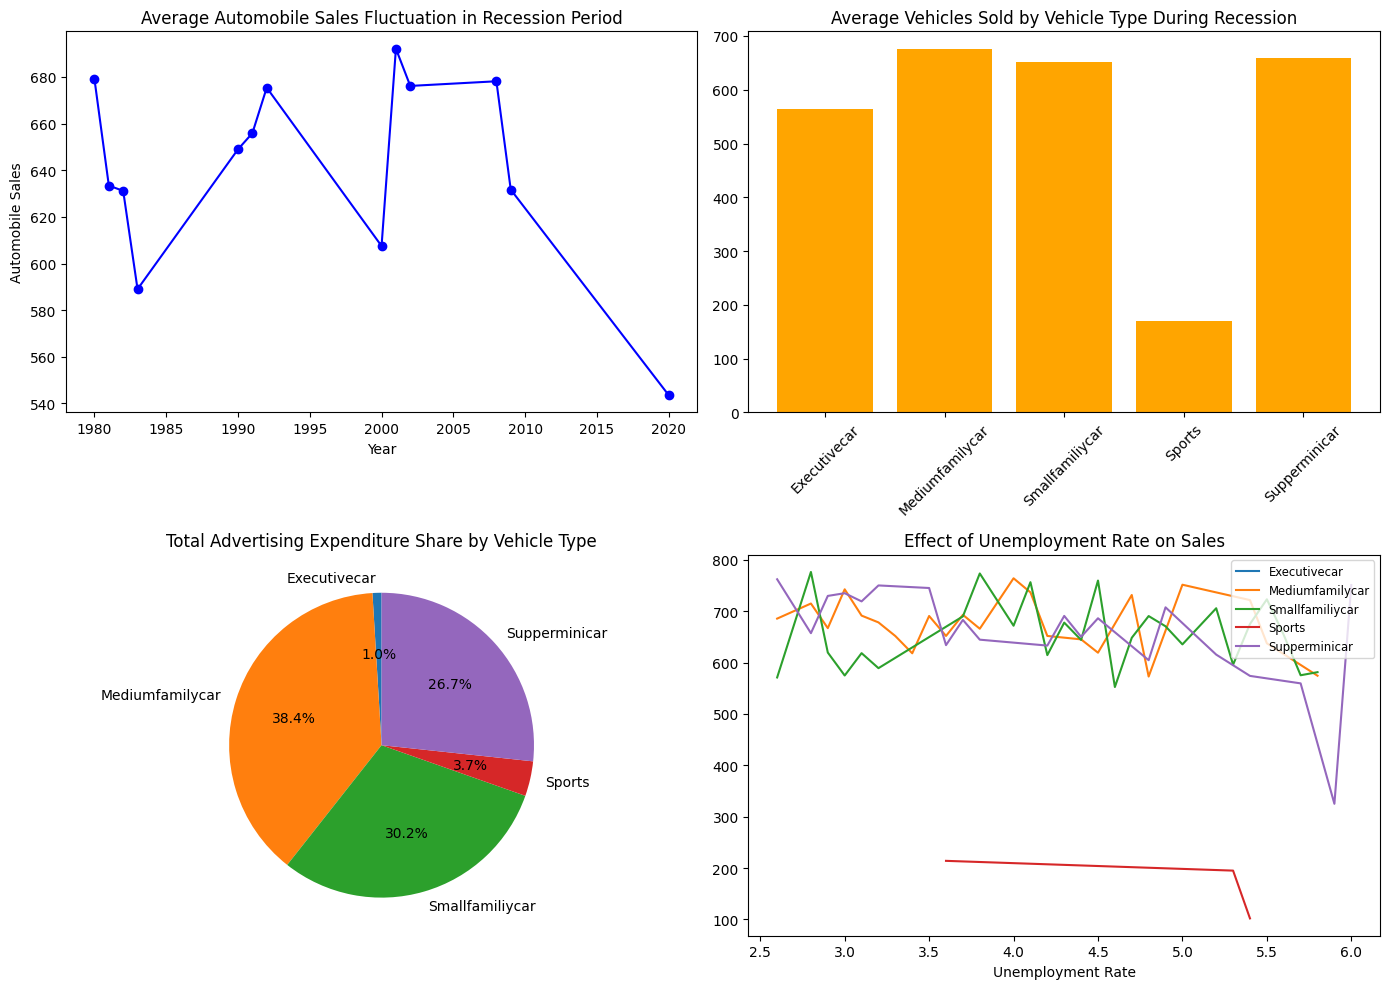

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter data for recession periods
recession_data = df[df['Recession'] == 1]

# Create the 4 recession graphs in a 2x2 grid layout
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Graph 1: Average Automobile Sales Fluctuation in Recession Period
yearly_rec = recession_data.groupby('Year')['Automobile_Sales'].mean().reset_index()
axes[0, 0].plot(yearly_rec['Year'], yearly_rec['Automobile_Sales'], marker='o', color='b')
axes[0, 0].set_title('Average Automobile Sales Fluctuation in Recession Period')
axes[0, 0].set_xlabel('Year')
axes[0, 0].set_ylabel('Automobile Sales')

# Graph 2: Average Vehicles Sold by Vehicle Type During Recession
avrg_veh = recession_data.groupby('Vehicle_Type')['Automobile_Sales'].mean().reset_index()
axes[0, 1].bar(avrg_veh['Vehicle_Type'], avrg_veh['Automobile_Sales'], color='orange')
axes[0, 1].set_title('Average Vehicles Sold by Vehicle Type During Recession')
axes[0, 1].tick_params(axis='x', rotation=45)

# Graph 3: Total Advertising Expenditure Share by Vehicle Type During Recession
exp_rec = recession_data.groupby('Vehicle_Type')['Advertising_Expenditure'].sum()
axes[1, 0].pie(exp_rec, labels=exp_rec.index, autopct='%1.1f%%', startangle=90)
axes[1, 0].set_title('Total Advertising Expenditure Share by Vehicle Type')

# Graph 4: Effect of Unemployment Rate on Vehicle Type and Sales
unemp_data = recession_data.groupby(['unemployment_rate', 'Vehicle_Type'])['Automobile_Sales'].mean().reset_index()
for v_type, group in unemp_data.groupby('Vehicle_Type'):
    axes[1, 1].plot(group['unemployment_rate'], group['Automobile_Sales'], label=v_type)
axes[1, 1].set_title('Effect of Unemployment Rate on Sales')
axes[1, 1].set_xlabel('Unemployment Rate')
axes[1, 1].legend(loc='upper right', fontsize='small')

plt.tight_layout()

# Save the figure as the exact file name required
plt.savefig('RecessionReportgraphs.png')
print("RecessionReportgraphs.png created successfully!")
plt.show()